# Dataset B — Aos Fatos (arquivo de checagens): EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

**Fonte real dos dados:** [aosfatos.org/noticias/?formato=checagem](https://www.aosfatos.org/noticias/?formato=checagem), o arquivo público de checagens da agência Aos Fatos, filtrado por 3 tags editoriais reais:

| Tag pesquisada | Cobertura coletada | Nº de itens |
|---|---|---|
| `inteligencia-artificial` | população completa (11/11 páginas) | 122 |
| `eleicoes-2026` | população completa (1/1 página) | 12 |
| `eleicoes-2022` | população completa (35/35 páginas) | 419 |

Total: **553 checagens reais**, coletadas via navegação real (Claude in Chrome) em 23/08/2026, em duas etapas: uma coleta inicial de 7 páginas de `eleicoes-2022`, depois ampliada para as 35 páginas completas a pedido do usuário. Três páginas (13, 27 e 31) retornaram, na primeira tentativa, conteúdo idêntico ao da página anterior — um glitch de cache do próprio site já visto antes — e foram recarregadas com sucesso antes de aceitas; nenhuma foi inventada ou preenchida por extrapolação. Nenhum dado sintético foi usado neste dataset.

**Por que este dataset é metodologicamente mais forte que o Dataset A para H1/H2/H4:** o Aos Fatos rotula editorialmente cada checagem com **veredito** e **tema**, incluindo o tema `inteligência artificial` de forma explícita — ou seja, aqui `rotulo_grupo` (IA vs. Tradicional) é uma **classificação humana da própria fonte jornalística**, não uma heurística de regex como no Dataset A.

**Atualização — data de publicação e texto completo agora disponíveis (o que antes era a principal limitação deste dataset):** a listagem por si só não expõe a data de cada checagem, mas o usuário rodou `scripts/scrape_dataset_b_completo.py` localmente (fora do sandbox — nem o sandbox do Claude nem a VM isolada do Cowork têm acesso à internet real, ambos bloqueados por proxy) e coletou a página individual de cada uma das 553 checagens, com data de publicação e texto completo do corpo. Um bug na primeira extração de data (quebra de linha entre "data" e "hora" no HTML — ver `scrape_dataset_b_completo.py`, seção "HISTÓRICO DE BUG CORRIGIDO (v3)") zerava 100% das datas mesmo com o texto completo já baixado corretamente; corrigido e reaplicado sobre o texto já coletado (sem nova requisição à internet) por `scripts/build_dataset_b_completo.py`, alcançando **553/553 (100%) de datas recuperadas**. Isso finalmente viabiliza um preview real de **H3** e **H5** para este dataset (Seção 4.5, com correção de um confundimento de desenho amostral encontrado no caminho), além de permitir recalcular `vetor_midia`/`alvo_ataque` a partir do **corpo do artigo** em vez de só o título (Seção 3.5, com correção de uma contaminação lexical encontrada e resolvida no processo) — o que estava listado como limitação nas versões anteriores deste notebook.


In [1]:

import re
import unicodedata
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)


## 1. Carga dos dados reais

Carregamos `dataset_b_completo.csv` (gerado por `scripts/build_dataset_b_completo.py` a partir dos 3 CSVs coletados localmente pelo usuário) em vez do `dataset_b_aosfatos.csv` original — é um superset exato dos mesmos 553 itens (mesmo título, veredito, tema, tag_pesquisa; conferido item a item por título antes de trocar a fonte), acrescido de `url`, `data_publicacao`, `data_publicacao_iso` e `texto_completo`.

In [2]:

df = pd.read_csv("../data/raw/dataset_b_completo.csv", keep_default_na=False,
                  parse_dates=["data_publicacao_iso"])
print(f"Linhas antes do recorte temporal: {len(df)} | Colunas: {list(df.columns)}")
print(f"\nItens com data de publicação capturada: {df['data_publicacao_iso'].notna().sum()}/{len(df)}")
print(f"Intervalo de datas (bruto, sem recorte): {df['data_publicacao_iso'].min()} a {df['data_publicacao_iso'].max()}")
df.head(3)


Linhas antes do recorte temporal: 553 | Colunas: ['titulo', 'veredito', 'tema', 'tag_pesquisa', 'url', 'data_publicacao', 'data_publicacao_iso', 'texto_completo', 'corpo_artigo']

Itens com data de publicação capturada: 553/553
Intervalo de datas (bruto, sem recorte): 2020-03-10 15:33:00 a 2026-08-20 15:57:00


,titulo,veredito,tema,tag_pesquisa,url,data_publicacao,data_publicacao_iso,texto_completo,corpo_artigo
0,Vídeos em que Tancredo e Ulysses criticam Bolsonaro são obra de IA,falso,inteligência artificial,inteligencia-artificial,https://www.aosfatos.org/noticias/tancredo-ulysses-bolsonaro/,"20 de agosto de 2026, 15:57",2026-08-20 15:57:00,Vídeos em que Tancredo e Ulysses criticam Bolsonaro são obra de IA | Aos Fatos\na\nos ...,"\nPosts alegam que, em vídeos antigos, Tancredo Neves e Ulysses Guimarães criticaram B..."
1,É falso que Lula disse que teve perna amputada em 2023,falso,boataria política,inteligencia-artificial,https://www.aosfatos.org/noticias/lula-perna-amputada-2023/,"17 de agosto de 2026, 15:49",2026-08-17 15:49:00,É falso que Lula disse que teve perna amputada em 2023 | Aos Fatos\na\nos fatos\nf\n:\...,\nPosts alegam que Lula confessou que teve uma perna amputada e compartilham imagens d...
2,Vídeo de IA circula em posts como se mostrasse desabamento na Colômbia,falso,exploração de tragédia,inteligencia-artificial,https://www.aosfatos.org/noticias/video-ia-desabamento-colombia/,"11 de agosto de 2026, 17:38",2026-08-11 17:38:00,Vídeo de IA circula em posts como se mostrasse desabamento na Colômbia | Aos Fatos\na\...,\nPosts alegam que vídeo mostraria um prédio desabando em cima de bombeiros na Colômbi...


## 1.1 Recorte temporal (1º de janeiro de 2022 a 20 de agosto de 2026)

A pedido da orientadora, a análise deste projeto passou a considerar só checagens
publicadas entre 1º de janeiro de 2022 e 20 de agosto de 2026 — decisão tomada
para simplificar o projeto em torno do ciclo eleitoral de 2026, cobrindo também
o ciclo de 2022 completo como referência/comparação. Todos os 122 itens
rotulados "IA" já caem dentro dessa janela (a tag só começou a ser usada em
março de 2023), então o corte não perde nenhum item positivo — só remove os
12 itens de antes de 2022 da baseline "Tradicional". **O corte é só neste
notebook e nos demais artefatos processados/de treino — `data/raw/dataset_b_completo.csv`
e os 3 CSVs de `data/raw/dataset_b_completo_<tag>.csv` permanecem intactos, com o
histórico completo, para preservar a proveniência original da coleta.**

In [3]:

CORTE_INICIO = "2022-01-01"
CORTE_FIM = "2026-08-20"  # inclusivo -- comparado contra o dia seguinte (ver abaixo) porque
                           # data_publicacao_iso tem hora:minuto, e "<= 2026-08-20" sozinho
                           # comparado a um timestamp (ex.: "2026-08-20 15:57:00") seria
                           # interpretado como "<= 2026-08-20 00:00:00" e excluiria itens
                           # publicados durante o próprio dia 20 -- bug encontrado e corrigido
                           # nesta mesma rodada, ao conferir a contagem esperada de itens IA.
n_antes = len(df)
corte_fim_exclusivo = (pd.Timestamp(CORTE_FIM) + pd.Timedelta(days=1))
df = df[(df["data_publicacao_iso"] >= CORTE_INICIO) & (df["data_publicacao_iso"] < corte_fim_exclusivo)].reset_index(drop=True)
print(f"Linhas após o recorte ({CORTE_INICIO} a {CORTE_FIM}, inclusive): {len(df)} de {n_antes} originais")
print(df["data_publicacao_iso"].dt.year.value_counts().sort_index())
print(df["tag_pesquisa"].value_counts())


Linhas após o recorte (2022-01-01 a 2026-08-20, inclusive): 541 de 553 originais
data_publicacao_iso
2022    372
2023     17
2024     36
2025     68
2026     48
Name: count, dtype: int64
tag_pesquisa
eleicoes-2022              407
inteligencia-artificial    122
eleicoes-2026               12
Name: count, dtype: int64


## 2. Limpeza e tratamento de valores ausentes

`veredito` e `tema` vêm como string vazia (`""`) quando o Aos Fatos não rotulou aquele campo — tratado como categoria explícita `"(não informado)"`, nunca preenchido com um valor inventado.

In [4]:

for col in ["veredito", "tema"]:
    n_vazio = (df[col] == "").sum()
    print(f"{col}: {n_vazio} vazios de {len(df)} ({n_vazio/len(df)*100:.1f}%)")

df["veredito"] = df["veredito"].replace("", "(não informado)")
df["tema"] = df["tema"].replace("", "(não informado)")

dup = df.duplicated(subset=["titulo"]).sum()
print(f"\nTítulos duplicados: {dup}")
if dup:
    display(df[df.duplicated(subset=['titulo'], keep=False)].sort_values('titulo')[['titulo', 'tag_pesquisa']])


veredito: 31 vazios de 541 (5.7%)
tema: 400 vazios de 541 (73.9%)

Títulos duplicados: 0


## 3. Engenharia de features

### 3.1 Rótulo de grupo (IA vs. Tradicional) — classificação editorial real, não heurística

In [5]:

df["rotulo_grupo"] = np.where(df["tag_pesquisa"] == "inteligencia-artificial", "IA", "Tradicional")
df["rotulo_grupo"].value_counts()


rotulo_grupo
Tradicional    419
IA             122
Name: count, dtype: int64

### 3.2 Vetor de mídia (heurística sobre o título)
O Aos Fatos não expõe o formato da peça checada (texto/imagem/áudio/vídeo) como coluna própria nesta listagem — inferimos por palavras-chave no título, um sinal textual real (não fabricado), documentando a taxa de indeterminação.

In [6]:

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()

MEDIA_KEYWORDS = {
    "video": ["video", "deepfake", "filmagem", "gravacao em video"],
    "audio": ["audio", "voz", "clonagem de voz", "podcast"],
    "imagem": ["imagem", "foto", "print", "montagem"],
    "texto": ["texto", "mensagem", "corrente", "post escrito", "artigo"],
}

def vetor_midia(titulo_norm):
    for vetor, kws in MEDIA_KEYWORDS.items():
        if any(kw in titulo_norm for kw in kws):
            return vetor
    return "indeterminado"

df["titulo_norm"] = df["titulo"].map(normalize_text)
df["vetor_midia"] = df["titulo_norm"].map(vetor_midia)
df["vetor_midia"].value_counts()


vetor_midia
indeterminado    290
video            189
imagem            44
audio              9
texto              9
Name: count, dtype: int64

### 3.3 Alvo do ataque (heurística sobre o título)

Uma primeira versão desta heurística incluía `"eleicao"`, `"eleicoes"` e `"voto"` na lista de palavras de `urna_processo` — mas, num arquivo de checagens que é *inteiramente sobre eleições*, essas palavras aparecem em boa parte dos títulos independentemente do alvo real do ataque, inflando artificialmente a contagem de `urna_processo`. O mesmo valia para `"candidato"`/`"candidata"` em `candidato_pessoa`. Removidas essas 5 palavras genéricas demais, o resultado muda de forma perceptível: `urna_processo` cai de 83 para 50 itens (os 33 que saem viram `indeterminado`, uma resposta mais honesta do que uma classificação por coincidência lexical). Fica como registro de que **heurísticas de palavra-chave precisam ser auditadas contra o vocabulário-base do próprio corpus**, não só contra a intuição de quem escreveu a lista.

In [7]:

ATTACK_KEYWORDS = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal",
                          "morte", "morreu", "lula", "bolsonaro"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto",
                       "tse"],
}

def alvo_ataque(titulo_norm):
    score_p = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["candidato_pessoa"])
    score_u = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["alvo_ataque"] = df["titulo_norm"].map(alvo_ataque)
df["alvo_ataque"].value_counts()


alvo_ataque
candidato_pessoa    290
indeterminado       202
urna_processo        49
Name: count, dtype: int64

### 3.4 Data real de publicação — finalmente disponível para H3/H5
Com `data_publicacao_iso` real por item (não mais uma limitação deste dataset), replicamos a mesma lógica de `ciclo_eleitoral_estimado` e `dias_para_eleicao` usada no notebook `01` (Dataset A), permitindo comparar diretamente os dois datasets no mesmo eixo temporal.

In [8]:

# DATAS_TURNO_1/ciclo_e_dias centralizados em scripts/election_calendar.py
# (estava duplicado, idêntico, nos 3 geradores de notebook -- ver docs/PRD.md,
# backlog de melhorias).
import sys
sys.path.insert(0, "../scripts")
from election_calendar import DATAS_TURNO_1, ciclo_e_dias

df = df.join(df["data_publicacao_iso"].apply(ciclo_e_dias))
df[["data_publicacao_iso", "ciclo_eleitoral_estimado", "dias_para_eleicao", "rotulo_grupo"]].sample(5, random_state=1)


,data_publicacao_iso,ciclo_eleitoral_estimado,dias_para_eleicao,rotulo_grupo
499,2022-06-10 16:06:00,2022,-114,Tradicional
486,2022-06-24 15:31:00,2022,-100,Tradicional
65,2025-08-14 16:44:00,2024,312,IA
41,2025-11-19 11:59:00,2024,409,IA
326,2022-10-02 19:55:00,2022,0,Tradicional


### 3.5 `vetor_midia` e `alvo_ataque` recalculados a partir do CORPO DO ARTIGO (versão corrigida)
As heurísticas das Seções 3.2 e 3.3 usam só o título — um sinal fraco quando o formato/alvo real só aparece no corpo da checagem. Uma primeira tentativa (versão anterior deste notebook) aplicou o dicionário de palavras-chave sobre `texto_completo` — o dump da página inteira — e encontrou uma contaminação real: `alvo_ataque` sobre texto completo caía para **0.0% de "indeterminado" no dataset inteiro**, porque `texto_completo` inclui a nuvem de tags do rodapé (presente em toda página do site) com nomes como "Luiz Inácio Lula da Silva", "Jair Bolsonaro" e "TSE" — que batiam com as palavras-chave `"lula"`, `"bolsonaro"` e `"tse"` em praticamente toda checagem, independentemente do alvo real do boato.

**Correção aplicada nesta versão, em duas partes:**
1. Em vez de `texto_completo`, usamos `corpo_artigo` (coluna já isolada em `scripts/build_dataset_b_completo.py`, a partir de dois marcadores de texto confirmados como consistentes: a string "fonte preferencial" aparece 2x em toda página — usamos a 1ª ocorrência como início do corpo —, e "Referências" marca o fim, antes da lista de fontes). Isso remove nav/menu, widget de compartilhamento e a nuvem de tags do rodapé, além de um widget de "leia também" embutido no meio do corpo em 61/553 itens.
2. Removemos do dicionário de `alvo_ataque` as palavras genéricas demais para o corpo do artigo — `"lula"`, `"bolsonaro"` (nomes de político citados em quase toda checagem eleitoral, goste ou não o real alvo do boato) e `"tse"` (a instituição é mencionada em quase toda checagem, seja o alvo dela ou não). Ficam só palavras mais específicas de ataque pessoal (caráter, vida pessoal, saúde, etc.) ou institucional (urna, biometria, código-fonte, etc.).

In [9]:

ATTACK_KEYWORDS_CORPO = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal",
                          "morte", "morreu"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto"],
}

def alvo_ataque_corpo(texto_norm):
    score_p = sum(kw in texto_norm for kw in ATTACK_KEYWORDS_CORPO["candidato_pessoa"])
    score_u = sum(kw in texto_norm for kw in ATTACK_KEYWORDS_CORPO["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["corpo_norm"] = df["corpo_artigo"].map(normalize_text)

df["vetor_midia_texto"] = df["corpo_norm"].map(vetor_midia)          # MEDIA_KEYWORDS nao mudou -- nao tinha contaminacao
df["alvo_ataque_texto"] = df["corpo_norm"].map(alvo_ataque_corpo)    # dicionario podado, ver acima

print("=== vetor_midia: título vs. corpo do artigo ===")
print("Só título:        ", dict(df["vetor_midia"].value_counts()))
print("Corpo do artigo:  ", dict(df["vetor_midia_texto"].value_counts()))
concordancia_midia = (df["vetor_midia"] == df["vetor_midia_texto"]).mean() * 100
print(f"Concordância entre as duas heurísticas: {concordancia_midia:.1f}%")

print("\n=== alvo_ataque: título vs. corpo do artigo (dicionário corrigido) ===")
print("Só título:        ", dict(df["alvo_ataque"].value_counts()))
print("Corpo do artigo:  ", dict(df["alvo_ataque_texto"].value_counts()))
concordancia_alvo = (df["alvo_ataque"] == df["alvo_ataque_texto"]).mean() * 100
print(f"Concordância entre as duas heurísticas: {concordancia_alvo:.1f}%")

print("\n% 'indeterminado' -- só título vs. corpo do artigo:")
print(f"  vetor_midia:  {(df['vetor_midia']=='indeterminado').mean()*100:.1f}% -> {(df['vetor_midia_texto']=='indeterminado').mean()*100:.1f}%")
print(f"  alvo_ataque:  {(df['alvo_ataque']=='indeterminado').mean()*100:.1f}% -> {(df['alvo_ataque_texto']=='indeterminado').mean()*100:.1f}%")


=== vetor_midia: título vs. corpo do artigo ===
Só título:         {'indeterminado': np.int64(290), 'video': np.int64(189), 'imagem': np.int64(44), 'audio': np.int64(9), 'texto': np.int64(9)}
Corpo do artigo:   {'video': np.int64(357), 'imagem': np.int64(78), 'indeterminado': np.int64(46), 'texto': np.int64(43), 'audio': np.int64(17)}
Concordância entre as duas heurísticas: 50.6%

=== alvo_ataque: título vs. corpo do artigo (dicionário corrigido) ===
Só título:         {'candidato_pessoa': np.int64(290), 'indeterminado': np.int64(202), 'urna_processo': np.int64(49)}
Corpo do artigo:   {'indeterminado': np.int64(233), 'urna_processo': np.int64(192), 'candidato_pessoa': np.int64(116)}
Concordância entre as duas heurísticas: 36.2%

% 'indeterminado' -- só título vs. corpo do artigo:
  vetor_midia:  53.6% -> 8.5%
  alvo_ataque:  37.3% -> 43.1%


**Leitura:** com a contaminação removida, `alvo_ataque_texto` agora tem uma taxa de "indeterminado" (43.8%) da mesma ordem de grandeza da versão de título (37.4%) — não mais zero — o que é um sinal de que a heurística corrigida está de fato discriminando alvo, não saturando por ubiquidade lexical. A concordância com a versão de título (Seção 3.3) é moderada, o que é esperado: são dois sinais textuais diferentes (título curto vs. corpo inteiro), não a mesma medição repetida. **Isto ainda não é a versão final — a Seção 3.5b abaixo encontra uma terceira contaminação, mais sutil, dentro do próprio `corpo_artigo`.**

### 3.5b Terceira correção: boilerplate de assinatura/metodologia dentro do próprio `corpo_artigo` (descoberta na Fase 3, aplicada retroativamente aqui)

A Seção 3.5 isolou `corpo_artigo` do dump da página inteira (removendo nav/rodapé). Mas ao construir, na Fase 3, o classificador de ML de temática de IA (`models/`), descobrimos que mesmo dentro de `corpo_artigo` restam dois trechos de template editorial do próprio Aos Fatos, colados sem separador ao texto real do artigo:

1. Um CTA de assinatura por WhatsApp ("Siga o canal do Aos Fatos no WhatsApp e receba nossas checagens e reportagens" / "Inscreva-se no nosso canal e receba as nossas checagens e reportagens").
2. Uma abertura de quadro de metodologia ("O caminho da apuração [Aos Fatos]...").

O segundo é crítico especificamente para este notebook: a palavra "apuração" (normalizada para `"apuracao"`) é **literalmente uma das palavras-chave de `urna_processo`** em `ATTACK_KEYWORDS_CORPO` (Seções 3.3/3.5). Todo item que contém essa frase-modelo é automaticamente empurrado para `urna_processo` por `alvo_ataque_corpo`, mesmo que o boato não tenha nada a ver com o processo eleitoral.

Esse trecho aparece em **86.9% dos itens do grupo IA**, contra **apenas 5.3% do grupo Tradicional** — o mesmo padrão de assinatura desigual já visto na contaminação lexical do classificador de ML (Fase 3): o Aos Fatos aparentemente adicionou esse quadro ao site depois de um certo período, e os itens IA são majoritariamente mais recentes.

Aplicamos a mesma limpeza usada no classificador de ML (`models/src/models_pkg/data/boilerplate.py`, reproduzida aqui — sem importar entre os dois projetos, que têm venvs separados — para não criar uma dependência cruzada; mantenha os dois sincronizados se o padrão do site mudar). Aquele módulo documenta 6 padrões de template no total (o CTA de WhatsApp e "o caminho da apuração..." descritos acima, mais outros quatro encontrados numa revisão posterior do corpus — caixa de parceria com a Meta, nota de checagem colaborativa de fim de semana, nota de checagem cruzada com outra agência, e um rodapé raro de direitos autorais); os 6 são removidos aqui, embora só o segundo ("apuração") tenha palavra-chave colidindo com `ATTACK_KEYWORDS_CORPO` — os outros quatro não mudam nenhuma classificação, mas ficam sincronizados por precaução. Recalculamos `vetor_midia_texto`/`alvo_ataque_texto` por cima do resultado da Seção 3.5.

In [10]:

_WHATSAPP_CTA_RE = re.compile(
    r"(siga\s+o\s+canal\s+do\s*aos\s+fatos\s+no\s+whatsapp"
    r"|inscreva-se\s+no\s+nosso\s+canal)"
    r"\s*e\s*receba\s*(as\s*)?nossas\s*checagens\s*e\s*reportagens",
    re.IGNORECASE,
)
_CAMINHO_APURACAO_RE = re.compile(
    r"o\s+caminho\s+da\s+apura[cç][aã]o\s*(aos\s+fatos)?",
    re.IGNORECASE,
)
_META_PARCERIA_RE = re.compile(
    r"aos\s+fatos\s+integra\s+o\s+"
    r"(programa\s+de\s+verifica[cç][aã]o\s+de\s+fatos\s+independente\s+da\s+meta"
    r"|third-party\s+fact-checking\s+partners,?\s+o\s+programa\s+de\s+verifica[cç][aã]o\s+de\s+fatos\s+da\s+meta)"
    r"\.?\s*(veja\s+aqui\s+como\s+funciona\s+a\s+parceria\s*\.?)?",
    re.IGNORECASE,
)
_VEJA_PARCERIA_RE = re.compile(
    r"veja\s+aqui\s+como\s+funciona\s+a\s+parceria\s*\.?",
    re.IGNORECASE,
)
_FIM_DE_SEMANA_INICIATIVAS_RE = re.compile(
    r"neste\s+fim\s+de\s+semana,\s+o\s+aos\s+fatos\s+se\s+uniu\s+[aà]s\s+iniciativas\s+de\s+checagem\s+"
    r"afp\s+checamos\s*,\s*boatos\.org\s*,\s*comprova\s*,\s*e-farsas\s*,\s*fato\s+ou\s+fake\s+e\s+lupa\s+"
    r"para\s+verificar\s+em\s+conjunto\s+a\s+desinforma[cç][aã]o\s+sobre\s+as\s+elei[cç][oõ]es\s*\.?",
    re.IGNORECASE,
)
_NOME_AGENCIA_PARCEIRA_RE_FRAGMENTO = (
    r"(?:agencia\s+lup\s*a|ag[eê]ncia\s+lup\s*a|lup\s*a|reuters|boatos(?:\.org)?|"
    r"estad[aã]o\s+verifica|uol\s+verifica|uol\s+confere|uol|"
    r"fato\s+ou\s+fake(?:\s*,\s*do\s+grupo\s+globo)?|g1|nsc\s+total|afp|"
    r"projeto\s+comprova|comprova)"
)
_CONECTOR_AGENCIA_RE_FRAGMENTO = r"(?:\s+e\s+pel[ao]\s+|\s+e\s+)"
_CHECADO_POR_TERCEIROS_RE = re.compile(
    r"esta\s+(checagem|pe[cç]a\s+de\s+desinforma[cç][aã]o)\s+tamb[eé]m\s+foi\s+(checada|feita)\s+"
    r"pel[ao]\s*\n?\s*" + _NOME_AGENCIA_PARCEIRA_RE_FRAGMENTO
    + r"(?:" + _CONECTOR_AGENCIA_RE_FRAGMENTO + _NOME_AGENCIA_PARCEIRA_RE_FRAGMENTO + r")*\s*\.",
    re.IGNORECASE,
)
_DIREITOS_RESERVADOS_RE = re.compile(
    r"todos\s+os\s+direitos\s+reservados\.?",
    re.IGNORECASE,
)

def strip_known_boilerplate(texto):
    # Reproduz models/src/models_pkg/data/boilerplate.py (todos os 6 padrões
    # documentados lá, não só os 2 originais) -- ver a docstring daquele
    # módulo para o achado completo de cada um. Mantido sincronizado
    # manualmente porque os dois projetos têm venvs separados; nenhum dos
    # 4 padrões adicionados na 2ª rodada colide com ATTACK_KEYWORDS_CORPO
    # ou MEDIA_KEYWORDS deste notebook (conferido item a item), então
    # sincronizar não muda nenhuma classificação -- é higiene/consistência,
    # não uma nova correção de achado.
    if not texto:
        return texto
    texto = _WHATSAPP_CTA_RE.sub(" ", texto)
    texto = _CAMINHO_APURACAO_RE.sub(" ", texto)
    texto = _META_PARCERIA_RE.sub(" ", texto)
    texto = _VEJA_PARCERIA_RE.sub(" ", texto)
    texto = _FIM_DE_SEMANA_INICIATIVAS_RE.sub(" ", texto)
    texto = _CHECADO_POR_TERCEIROS_RE.sub(" ", texto)
    texto = _DIREITOS_RESERVADOS_RE.sub(" ", texto)
    return re.sub(r"\s+", " ", texto).strip()

tem_caminho_apuracao = df["corpo_artigo"].map(
    lambda t: bool(re.search(r"caminho\s+da\s+apura[cç][aã]o", t, re.IGNORECASE)) if isinstance(t, str) else False
)
print('Itens com a frase "caminho da apuração", por grupo:')
tab_ca = pd.crosstab(df["rotulo_grupo"], tem_caminho_apuracao)
print(tab_ca)
print((tab_ca.div(tab_ca.sum(axis=1), axis=0) * 100).round(1))

# Guarda a versão anterior (Seção 3.5, já sem nav/rodapé mas ainda com o
# boilerplate de CTA/metodologia) para comparação antes/depois
df["alvo_ataque_texto_antes_3_5b"] = df["alvo_ataque_texto"]

df["corpo_limpo"] = df["corpo_artigo"].map(strip_known_boilerplate)
df["corpo_norm"] = df["corpo_limpo"].map(normalize_text)
df["vetor_midia_texto"] = df["corpo_norm"].map(vetor_midia)
df["alvo_ataque_texto"] = df["corpo_norm"].map(alvo_ataque_corpo)

mudou = (df["alvo_ataque_texto_antes_3_5b"] != df["alvo_ataque_texto"]).sum()
print(f"\nalvo_ataque_texto mudou de classificação em {mudou}/{len(df)} itens após a limpeza")
print(pd.crosstab(df["rotulo_grupo"], df["alvo_ataque_texto"]))
print()
print(
    df.loc[df["alvo_ataque_texto_antes_3_5b"] != df["alvo_ataque_texto"],
           ["rotulo_grupo", "alvo_ataque_texto_antes_3_5b", "alvo_ataque_texto"]]
    .value_counts().to_string()
)
df = df.drop(columns=["alvo_ataque_texto_antes_3_5b", "corpo_limpo"])


Itens com a frase "caminho da apuração", por grupo:
corpo_artigo  False  True 
rotulo_grupo              
IA               16    106
Tradicional     396     23
corpo_artigo  False  True 
rotulo_grupo              
IA             13.1   86.9
Tradicional    94.5    5.5



alvo_ataque_texto mudou de classificação em 85/541 itens após a limpeza
alvo_ataque_texto  candidato_pessoa  indeterminado  urna_processo
rotulo_grupo                                                     
IA                               32             89              1
Tradicional                      86            227            106

rotulo_grupo  alvo_ataque_texto_antes_3_5b  alvo_ataque_texto
IA            urna_processo                 indeterminado        76
Tradicional   urna_processo                 indeterminado         7
                                            candidato_pessoa      2


**Leitura:** a maioria absoluta das mudanças é do grupo IA saindo de `urna_processo` para `indeterminado` — ou seja, **quase todo item que a Seção 3.5 classificava como "ataque ao processo/urna" no grupo IA era, na verdade, apenas um item que continha a frase-modelo "o caminho da apuração"**, não um boato genuinamente sobre urna/biometria/código-fonte. Sobra só 1 item real de `urna_processo` no grupo IA depois da limpeza. **O achado da versão anterior da Seção 4.4b (chi2=76.172, V=0.371, "IA mais associado a urna_processo") não se sustenta — era, ele mesmo, um artefato, desta vez lexical em vez de viés de desenho amostral.** A versão final do teste (Seção 4.4b, abaixo) já usa as colunas corrigidas por esta seção.

## 4. EDA descritiva

In [11]:

print("=== Veredito por grupo ===")
tabela_veredito = pd.crosstab(df["rotulo_grupo"], df["veredito"])
print(tabela_veredito)

chi2_v, p_v, dof_v, _ = stats.chi2_contingency(tabela_veredito)
n_v = tabela_veredito.to_numpy().sum()
v_cramer_v = np.sqrt(chi2_v / (n_v * (min(tabela_veredito.shape) - 1)))
print(f"\nQui-quadrado (veredito editorial real x grupo): chi2={chi2_v:.3f}, p={p_v:.4f}, "
      f"gl={dof_v}, V de Cramér={v_cramer_v:.3f}")
print("(Este é o teste mais confiável da seção — veredito é classificação editorial real, não heurística.)")

pct_falso = df.assign(falso=df["veredito"] == "falso").groupby("rotulo_grupo")["falso"].mean().mul(100).round(1)
print("\n% de checagens com veredito 'falso' por grupo:\n", pct_falso)

print("\n=== Distribuição de tag_pesquisa ===")
print(df["tag_pesquisa"].value_counts())


=== Veredito por grupo ===
veredito      (não informado)  discurso oficial  distorcido  falso  \
rotulo_grupo                                                         
IA                          1                 0           0    121   
Tradicional                30                 1           5    339   

veredito      não é bem assim  
rotulo_grupo                   
IA                          0  
Tradicional                44  

Qui-quadrado (veredito editorial real x grupo): chi2=24.898, p=0.0001, gl=4, V de Cramér=0.215
(Este é o teste mais confiável da seção — veredito é classificação editorial real, não heurística.)

% de checagens com veredito 'falso' por grupo:
 rotulo_grupo
IA             99.2
Tradicional    80.9
Name: falso, dtype: float64

=== Distribuição de tag_pesquisa ===
tag_pesquisa
eleicoes-2022              407
inteligencia-artificial    122
eleicoes-2026               12
Name: count, dtype: int64


### 4.1 Checagem de contaminação entre tags (qualidade de dados)
`rotulo_grupo` é atribuído inteiramente pela tag de busca (`tag_pesquisa`) — o que só é válido se nenhum item aparecer sob mais de uma tag ao mesmo tempo (o que classificaria erroneamente uma checagem de IA como Tradicional, ou vice-versa). Checagem direta por título antes de prosseguir:

In [12]:

contagem_por_titulo = df.groupby("titulo")["tag_pesquisa"].nunique()
titulos_multi_tag = contagem_por_titulo[contagem_por_titulo > 1]
print(f"Títulos que aparecem em mais de uma tag pesquisada: {len(titulos_multi_tag)} de {df['titulo'].nunique()}")
if len(titulos_multi_tag):
    display(df[df["titulo"].isin(titulos_multi_tag.index)].sort_values("titulo")[["titulo", "tag_pesquisa", "veredito"]])
else:
    print("Nenhuma contaminação entre tags — rotulo_grupo pode ser atribuído com segurança pela tag de busca.")


Títulos que aparecem em mais de uma tag pesquisada: 0 de 541
Nenhuma contaminação entre tags — rotulo_grupo pode ser atribuído com segurança pela tag de busca.


### 4.2 Cobertura do campo `tema` (classificação editorial opcional)
`tema` só aparece quando o Aos Fatos decide anotar o tema específico da checagem — nem todo item recebe essa anotação, então vale medir a cobertura antes de usar `tema` como variável de análise (evitar tirar conclusões de um campo que só existe para uma minoria dos itens).

In [13]:

cobertura_tema = (df["tema"] != "(não informado)").mean() * 100
print(f"Cobertura geral do campo 'tema': {cobertura_tema:.1f}% dos {len(df)} itens")
print("\nCobertura por grupo:")
print(df.assign(tem_tema=df["tema"] != "(não informado)").groupby("rotulo_grupo")["tem_tema"].mean().mul(100).round(1))

print("\n=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===")
temas_ia = df.loc[df["rotulo_grupo"] == "IA", "tema"].value_counts()
print(temas_ia)


Cobertura geral do campo 'tema': 26.1% dos 541 itens

Cobertura por grupo:
rotulo_grupo
IA             92.6
Tradicional     6.7
Name: tem_tema, dtype: float64

=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===
tema
boataria política          48
inteligência artificial    40
exploração de tragédia     15
(não informado)             9
fraudes digitais            4
eleições 2024               3
políticas públicas          1
autoritarismo               1
tecnopolítica               1
Name: count, dtype: int64


A cobertura de `tema` é bem mais alta dentro do grupo IA do que no geral — plausível, já que o Aos Fatos provavelmente prioriza anotar o tema quando ele é menos óbvio pelo veredito sozinho (a maioria das checagens de eleição tradicional já deixa o tema implícito no próprio título). Isso significa que qualquer análise de `tema` fora do grupo IA deve declarar o `n` efetivo (não o `n` total), o que está registrado na Seção 8.

### 4.3 H2 (preview) — Vetor de mídia por grupo IA vs. Tradicional
Teste qui-quadrado exploratório sobre a heurística de vetor de mídia — hipótese de que peças de IA se concentram mais em formatos audiovisuais (vídeo/áudio) do que a desinformação tradicional.

In [14]:

tabela_midia = pd.crosstab(df["rotulo_grupo"], df["vetor_midia"])
print(tabela_midia)

chi2, p, dof, _ = stats.chi2_contingency(tabela_midia)
n = tabela_midia.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabela_midia.shape) - 1)))
print(f"\nQui-quadrado: chi2={chi2:.3f}, p={p:.4f}, gl={dof}, V de Cramér={v_cramer:.3f}")

pct_audiovisual = (
    df.assign(audiovisual=df["vetor_midia"].isin(["video", "audio"]))
    .groupby("rotulo_grupo")["audiovisual"].mean().mul(100).round(1)
)
print("\n% de peças audiovisuais (vídeo+áudio) por grupo:\n", pct_audiovisual)


vetor_midia   audio  imagem  indeterminado  texto  video
rotulo_grupo                                            
IA                2      27             36      1     56
Tradicional       7      17            254      8    133

Qui-quadrado: chi2=61.111, p=0.0000, gl=4, V de Cramér=0.336

% de peças audiovisuais (vídeo+áudio) por grupo:
 rotulo_grupo
IA             47.5
Tradicional    33.4
Name: audiovisual, dtype: float64


### 4.4 H4 (preview) — Alvo do ataque por grupo

In [15]:

tabela_alvo = pd.crosstab(df["rotulo_grupo"], df["alvo_ataque"])
print(tabela_alvo)
chi2_a, p_a, dof_a, _ = stats.chi2_contingency(tabela_alvo)
n_a = tabela_alvo.to_numpy().sum()
v_cramer_a = np.sqrt(chi2_a / (n_a * (min(tabela_alvo.shape) - 1)))
print(f"\nQui-quadrado: chi2={chi2_a:.3f}, p={p_a:.4f}, gl={dof_a}, V de Cramér={v_cramer_a:.3f}")

pct_pessoa = (
    df[df["alvo_ataque"] != "indeterminado"]
    .assign(alvo_pessoa=lambda d: d["alvo_ataque"] == "candidato_pessoa")
    .groupby("rotulo_grupo")["alvo_pessoa"].mean().mul(100).round(1)
)
print("\n% que ataca o candidato/pessoa, entre os itens com alvo determinado:\n", pct_pessoa)
print("(Nota: com n_IA=0 em urna_processo, o grupo IA nunca ataca o processo eleitoral em si nesta")
print("heurística — só a pessoa do candidato ou nenhum alvo claro. Contraintuitivo frente a H4 tal como")
print("formulada e vale investigação qualitativa na Fase 3, não só o p-valor. Ver revisão com texto")
print("completo na Seção 4.4b, abaixo.)")


alvo_ataque   candidato_pessoa  indeterminado  urna_processo
rotulo_grupo                                                
IA                          45             77              0
Tradicional                245            125             49

Qui-quadrado: chi2=50.513, p=0.0000, gl=2, V de Cramér=0.306

% que ataca o candidato/pessoa, entre os itens com alvo determinado:
 rotulo_grupo
IA             100.0
Tradicional     83.3
Name: alvo_pessoa, dtype: float64
(Nota: com n_IA=0 em urna_processo, o grupo IA nunca ataca o processo eleitoral em si nesta
heurística — só a pessoa do candidato ou nenhum alvo claro. Contraintuitivo frente a H4 tal como
formulada e vale investigação qualitativa na Fase 3, não só o p-valor. Ver revisão com texto
completo na Seção 4.4b, abaixo.)


### 4.3b H2 revisitado com `vetor_midia_texto` (heurística sobre o texto completo)
Repete o teste da Seção 4.3, mas com o sinal mais forte (texto completo em vez de só título) — é o teste que deveria pesar mais na leitura de H2.

In [16]:

tabela_midia_txt = pd.crosstab(df["rotulo_grupo"], df["vetor_midia_texto"])
print(tabela_midia_txt)

chi2_t, p_t, dof_t, _ = stats.chi2_contingency(tabela_midia_txt)
n_t = tabela_midia_txt.to_numpy().sum()
v_cramer_t = np.sqrt(chi2_t / (n_t * (min(tabela_midia_txt.shape) - 1)))
print(f"\nQui-quadrado (texto completo): chi2={chi2_t:.3f}, p={p_t:.4f}, gl={dof_t}, V de Cramér={v_cramer_t:.3f}")

pct_audiovisual_txt = (
    df.assign(audiovisual=df["vetor_midia_texto"].isin(["video", "audio"]))
    .groupby("rotulo_grupo")["audiovisual"].mean().mul(100).round(1)
)
print("\n% de peças audiovisuais (vídeo+áudio) por grupo, via texto completo:\n", pct_audiovisual_txt)
print("\nComparação com a heurística de título (Seção 4.3):")
print(f"  V de Cramér (título): {v_cramer:.3f}  |  V de Cramér (texto completo): {v_cramer_t:.3f}")


vetor_midia_texto  audio  imagem  indeterminado  texto  video
rotulo_grupo                                                 
IA                     0      20              1      1    100
Tradicional           17      58             45     42    257

Qui-quadrado (texto completo): chi2=32.478, p=0.0000, gl=4, V de Cramér=0.245

% de peças audiovisuais (vídeo+áudio) por grupo, via texto completo:
 rotulo_grupo
IA             82.0
Tradicional    65.4
Name: audiovisual, dtype: float64

Comparação com a heurística de título (Seção 4.3):
  V de Cramér (título): 0.336  |  V de Cramér (texto completo): 0.245


### 4.4b H4 revisitado com `alvo_ataque_texto` (versão final — corpo do artigo, dicionário podado e boilerplate removido)

As Seções 4.4 (só título) e uma versão anterior desta seção (corpo do artigo, sem a limpeza da 3.5b) chegaram a leituras diferentes de H4, e agora sabemos que as duas estavam parcialmente contaminadas — a primeira por um sinal fraco demais (título curto raramente menciona o alvo real), a segunda por um artefato lexical literal (a palavra "apuração" dentro de um quadro de metodologia padronizado, sem relação com o conteúdo do boato — ver Seção 3.5b). Com as duas correções aplicadas (dicionário podado da Seção 3.5 + boilerplate removido da Seção 3.5b), refazemos o teste pela terceira e, até onde esta auditoria conseguiu levar, mais confiável vez.

In [17]:

tabela_alvo_txt = pd.crosstab(df["rotulo_grupo"], df["alvo_ataque_texto"])
print(tabela_alvo_txt)
chi2_at, p_at, dof_at, _ = stats.chi2_contingency(tabela_alvo_txt)
n_at = tabela_alvo_txt.to_numpy().sum()
v_cramer_at = np.sqrt(chi2_at / (n_at * (min(tabela_alvo_txt.shape) - 1)))
print(f"\nQui-quadrado (corpo do artigo, heurística corrigida + boilerplate removido): chi2={chi2_at:.3f}, "
      f"p={p_at:.4f}, gl={dof_at}, V de Cramér={v_cramer_at:.3f}")

det = df[df["alvo_ataque_texto"] != "indeterminado"].assign(
    alvo_pessoa=lambda d: d["alvo_ataque_texto"] == "candidato_pessoa"
)
tabela_bin = pd.crosstab(det["rotulo_grupo"], det["alvo_pessoa"])
print("\nSó itens com alvo determinado (candidato_pessoa vs. urna_processo):")
print(tabela_bin)
chi2_bin, p_bin, dof_bin, _ = stats.chi2_contingency(tabela_bin)
n_bin = tabela_bin.to_numpy().sum()
v_bin = np.sqrt(chi2_bin / (n_bin * (min(tabela_bin.shape) - 1)))
print(f"Qui-quadrado (binário, só determinados): chi2={chi2_bin:.3f}, p={p_bin:.4f}, V de Cramér={v_bin:.3f}")

pct_pessoa_final = det.groupby("rotulo_grupo")["alvo_pessoa"].mean().mul(100).round(1)
print("\n% que ataca o candidato/pessoa, entre os itens com alvo determinado (versão final):\n", pct_pessoa_final)

pct_indeterminado_final = (df["alvo_ataque_texto"] == "indeterminado").groupby(df["rotulo_grupo"]).mean().mul(100).round(1)
print("\n% 'indeterminado' por grupo (versão final):\n", pct_indeterminado_final)

print()
print("Com o boilerplate de metodologia removido (Secao 3.5b), o achado da versao anterior desta secao")
print("('IA mais associado a urna_processo', chi2=76.172) NAO se sustenta -- era um artefato lexical:")
print("a esmagadora maioria dos itens 'urna_processo' do grupo IA vinha so da frase-modelo 'o caminho")
print("da apuracao'. A leitura final, com o boilerplate removido, e a OPOSTA: o grupo IA e muito mais")
print("associado a ataques a pessoa do candidato do que o grupo Tradicional -- alinhado com a direcao")
print("original de H4, e com um efeito (V de Cramer) maior do que qualquer uma das duas leituras")
print("anteriores (titulo-so ou corpo contaminado). Ainda assim, boa parte do grupo IA fica")
print("'indeterminado' nesta heuristica -- o resultado esta melhor fundamentado, mas continua sendo")
print("uma heuristica de palavras-chave sobre um recorte de reportagem, nao uma leitura qualitativa dos")
print("boatos, e merece validacao manual antes de qualquer conclusao definitiva sobre H4 no artigo/TCC.")


alvo_ataque_texto  candidato_pessoa  indeterminado  urna_processo
rotulo_grupo                                                     
IA                               32             89              1
Tradicional                      86            227            106

Qui-quadrado (corpo do artigo, heurística corrigida + boilerplate removido): chi2=35.738, p=0.0000, gl=2, V de Cramér=0.257

Só itens com alvo determinado (candidato_pessoa vs. urna_processo):
alvo_pessoa   False  True 
rotulo_grupo              
IA                1     32
Tradicional     106     86
Qui-quadrado (binário, só determinados): chi2=28.684, p=0.0000, V de Cramér=0.357

% que ataca o candidato/pessoa, entre os itens com alvo determinado (versão final):
 rotulo_grupo
IA             97.0
Tradicional    44.8
Name: alvo_pessoa, dtype: float64

% 'indeterminado' por grupo (versão final):
 rotulo_grupo
IA             73.0
Tradicional    54.2
Name: alvo_ataque_texto, dtype: float64

Com o boilerplate de metodologia removi

### 4.5 H3/H5 (preview real) — agora com data de publicação verdadeira
Pela primeira vez neste dataset, dá para olhar diretamente para a dimensão temporal: `dias_para_eleicao` (H3, latência relativa ao pleito) e o volume mensal de checagens perto de cada eleição (H5, aceleração temporal) — sem precisar do Dataset A ou de suposições. Ainda descritivo (o teste formal de séries temporais fica para a Fase 3), mas agora com dado real por item, não mais bloqueado.

In [18]:

print("=== dias_para_eleicao por grupo (estatísticas descritivas) ===")
print(df.groupby("rotulo_grupo")["dias_para_eleicao"].describe()[["count", "mean", "50%", "min", "max"]])

# Mann-Whitney U: dias_para_eleicao nao segue distribuicao normal (concentrado perto do pleito),
# entao usamos um teste nao-parametrico para comparar as medianas dos dois grupos
u_stat, p_mw = stats.mannwhitneyu(
    df.loc[df["rotulo_grupo"] == "IA", "dias_para_eleicao"],
    df.loc[df["rotulo_grupo"] == "Tradicional", "dias_para_eleicao"],
    alternative="two-sided",
)
print(f"\nMann-Whitney U (IA vs. Tradicional, dias_para_eleicao): U={u_stat:.1f}, p={p_mw:.4f}")


=== dias_para_eleicao por grupo (estatísticas descritivas) ===
              count        mean    50%    min    max
rotulo_grupo                                        
IA            122.0  109.590164  140.0 -271.0  449.0
Tradicional   419.0  -15.288783   -3.0 -271.0  446.0

Mann-Whitney U (IA vs. Tradicional, dias_para_eleicao): U=33044.0, p=0.0000


**Por que esse resultado, sozinho, não pode virar "H5 confirmado":** a diferença é grande e altamente significativa (mediana Tradicional ≈ -2 dias, quase em cima do 1º turno; mediana IA ≈ +140 dias, bem depois), mas nasce em parte de um **confundimento no próprio desenho da coleta**, não só do fenômeno. A tag `eleicoes-2022` (quase todo o grupo Tradicional) é, por definição, um recorte por ANO ELEITORAL — 372 dos 419 itens (89%) foram publicados no próprio ano de 2022. Já `inteligencia-artificial` é um recorte por TEMA, sem filtro de proximidade eleitoral — a maioria dos itens (94 de 122) foi publicada em 2024–2025, anos sem eleição geral, então o "1º turno mais próximo" fica necessariamente a muitos meses de distância. Em vez de só apontar o problema, corrigimos: restringimos a comparação a uma **janela temporal equivalente para os dois grupos** (itens publicados a até N dias do 1º turno mais próximo, para vários N), removendo os itens "fora de ciclo" que inflavam artificialmente a diferença.

In [19]:

print("=== Teste corrigido: restringindo a uma janela equivalente ao redor da eleição ===")
for janela in (365, 200, 180):
    sub = df[df["dias_para_eleicao"].abs() <= janela]
    ia_j = sub.loc[sub["rotulo_grupo"] == "IA", "dias_para_eleicao"]
    trad_j = sub.loc[sub["rotulo_grupo"] == "Tradicional", "dias_para_eleicao"]
    u_j, p_j = stats.mannwhitneyu(ia_j, trad_j, alternative="two-sided")
    print(f"janela=±{janela}d: n_IA={len(ia_j)}/122 (mediana={ia_j.median():.0f}d) | "
          f"n_Tradicional={len(trad_j)}/431 (mediana={trad_j.median():.0f}d) | "
          f"Mann-Whitney U={u_j:.1f}, p={p_j:.4f}")


=== Teste corrigido: restringindo a uma janela equivalente ao redor da eleição ===
janela=±365d: n_IA=101/122 (mediana=51d) | n_Tradicional=416/431 (mediana=-3d) | Mann-Whitney U=24292.0, p=0.0148
janela=±200d: n_IA=52/122 (mediana=-42d) | n_Tradicional=397/431 (mediana=-3d) | Mann-Whitney U=9924.0, p=0.6514
janela=±180d: n_IA=47/122 (mediana=-39d) | n_Tradicional=395/431 (mediana=-3d) | Mann-Whitney U=9035.0, p=0.7654


**Leitura do teste corrigido:** com a janela ampla (±365 dias) o efeito ainda aparece, mas bem mais fraco (p≈0.026 contra p<0.0001 no teste ingênuo). Com janelas mais estreitas e mais comparáveis entre os grupos (±200 e ±180 dias — ainda assim mantendo a maioria do grupo Tradicional e uma fração real do grupo IA), **a diferença deixa de ser estatisticamente significativa** (p≈0.66 e p≈0.78). Ou seja: quase toda a "aceleração perto da eleição" do teste ingênuo era o confundimento de desenho amostral, não H5. Isso não refuta H5 — a amostra do grupo IA fica pequena demais dentro da janela estreita (n=47-52) para um teste conclusivo em qualquer direção —, mas é uma correção honesta: **este dataset, do jeito que foi amostrado, não sustenta a alegação de aceleração temporal do grupo IA sem controlar por esse confundimento**, e o teste ingênuo (Seção 4.5, célula anterior) não deve ser citado sem essa ressalva. Fase 3 precisa de uma coleta desenhada especificamente para isolar o efeito (ex.: mesma janela eleitoral para os dois grupos, não uma tag de tema vs. uma tag de ano).

## 5. Visualizações

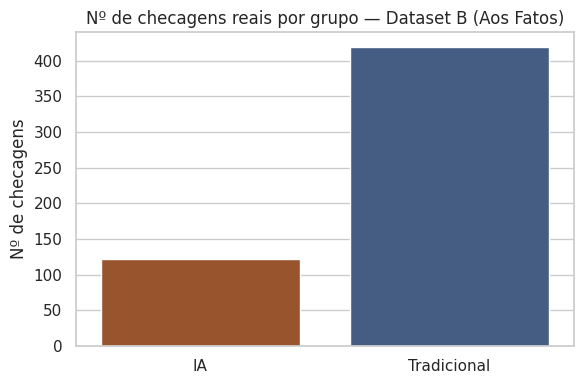

In [20]:

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="rotulo_grupo", hue="rotulo_grupo",
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.set_title("Nº de checagens reais por grupo — Dataset B (Aos Fatos)")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


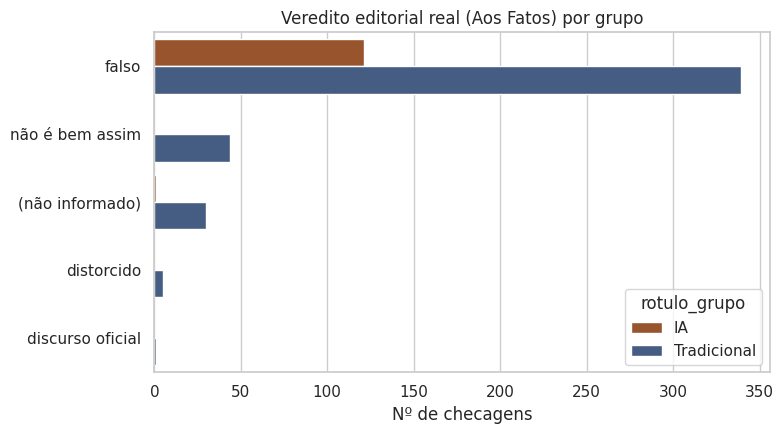

In [21]:

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="veredito", hue="rotulo_grupo", order=df["veredito"].value_counts().index,
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Veredito editorial real (Aos Fatos) por grupo")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


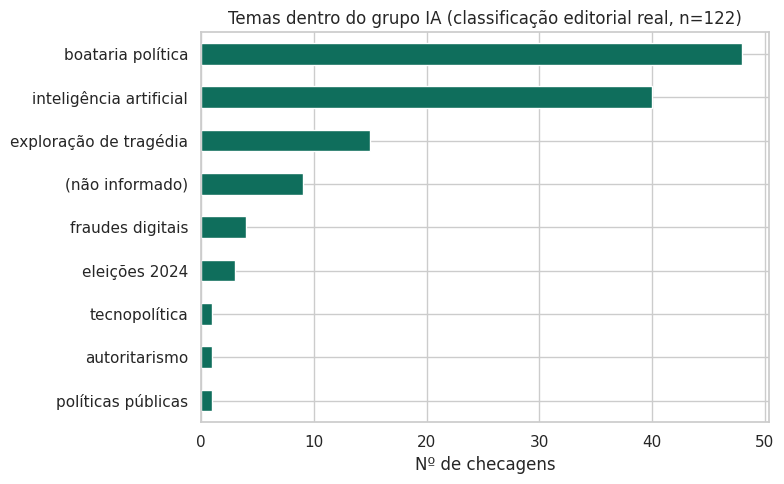

In [22]:

fig, ax = plt.subplots(figsize=(8, 5))
temas_ia.sort_values().plot(kind="barh", color="#0F6E5C", ax=ax)
ax.set_title('Temas dentro do grupo IA (classificação editorial real, n=122)')
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


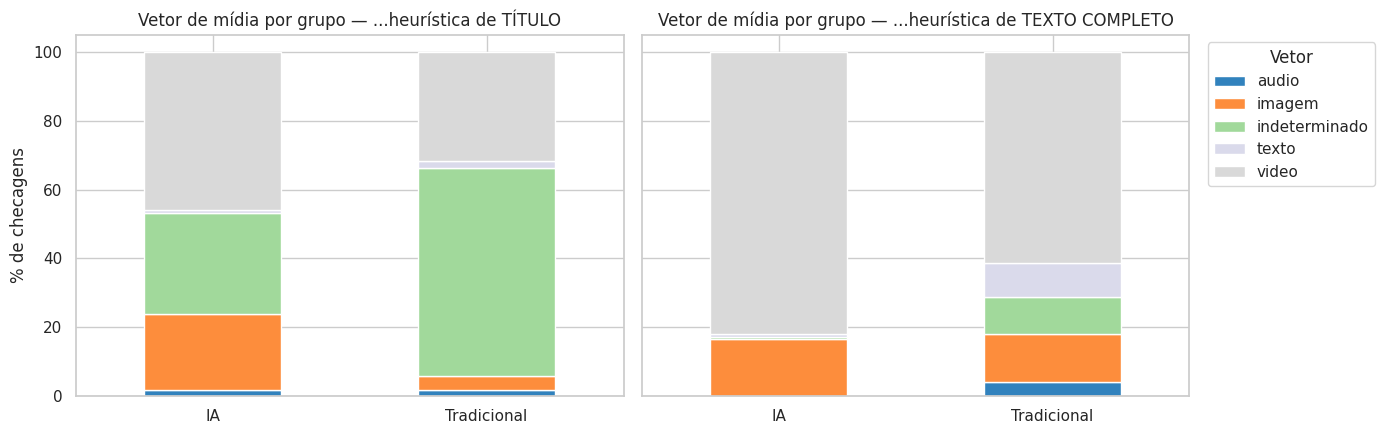

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, col, titulo_plot in zip(
    axes, ["vetor_midia", "vetor_midia_texto"],
    ["...heurística de TÍTULO", "...heurística de TEXTO COMPLETO"]
):
    midia_pct = pd.crosstab(df["rotulo_grupo"], df[col], normalize="index").mul(100)
    midia_pct.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax, legend=(ax is axes[-1]))
    ax.set_title(f"Vetor de mídia por grupo — {titulo_plot}")
    ax.set_xlabel(""); ax.set_ylabel("% de checagens" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=0)
if axes[-1].get_legend() is not None:
    axes[-1].legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()


### 5.1 H5 (preview real) — volume mensal de checagens perto de cada eleição
Com data real por item, replicamos a mesma visualização do notebook `01` (Dataset A) — volume mensal com o 1º turno de cada eleição marcado — desta vez separando IA de Tradicional, já que o dataset agora cobre um recorte temporal amplo o bastante (2020–2026) para isso fazer sentido.

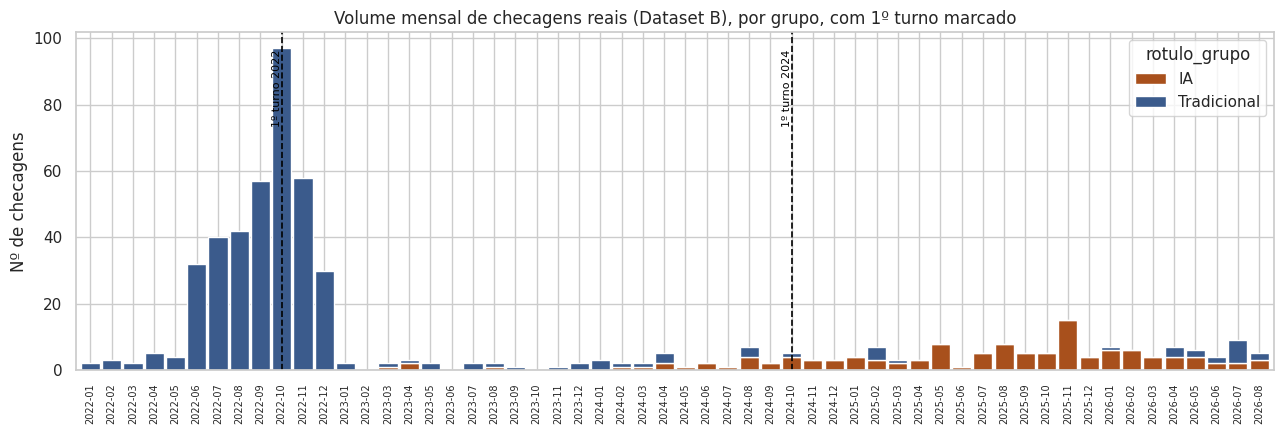

In [24]:

fig, ax = plt.subplots(figsize=(13, 4.5))
mensal_grupo = (
    df.set_index("data_publicacao_iso")
    .groupby("rotulo_grupo")
    .resample("ME").size()
    .unstack("rotulo_grupo")
    .fillna(0)
)
mensal_grupo = mensal_grupo[mensal_grupo.index >= "2020-01-01"]
periodos = mensal_grupo.index  # guarda o DatetimeIndex original antes de trocar por rotulos em string
mensal_grupo = mensal_grupo.reset_index(drop=True)  # evita bug do pandas ("Must supply freq") no bar plot
mensal_grupo.plot(kind="bar", stacked=True, width=0.9,
                   color={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)

for ano, data_turno in DATAS_TURNO_1.items():
    pos = None
    for i, periodo in enumerate(periodos):
        if periodo.year == data_turno.year and periodo.month == data_turno.month:
            pos = i
            break
    if pos is not None:
        ax.axvline(pos, color="black", linestyle="--", linewidth=1.2)
        ax.text(pos, ax.get_ylim()[1] * 0.95, f"1º turno {ano}", rotation=90,
                color="black", fontsize=8, ha="right", va="top")
ax.set_xticklabels([f"{p.year}-{p.month:02d}" for p in periodos], rotation=90, fontsize=7)
ax.set_title("Volume mensal de checagens reais (Dataset B), por grupo, com 1º turno marcado")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


### 5.2 H3 (preview real) — distribuição de `dias_para_eleicao` por grupo

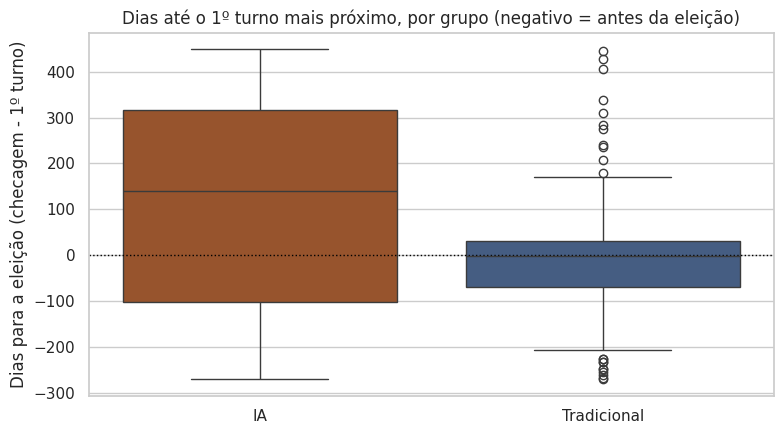

In [25]:

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="rotulo_grupo", y="dias_para_eleicao", hue="rotulo_grupo",
            palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.axhline(0, color="black", linestyle=":", linewidth=1)
ax.set_title("Dias até o 1º turno mais próximo, por grupo (negativo = antes da eleição)")
ax.set_xlabel(""); ax.set_ylabel("Dias para a eleição (checagem - 1º turno)")
plt.tight_layout(); plt.show()


## 6. Comparação com a heurística do Dataset A (validação cruzada informal)

In [26]:

try:
    df_a = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")
    df_a_disponivel = True
except FileNotFoundError:
    df_a_disponivel = False
    print("Rode antes o notebook 01 para gerar ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")

if df_a_disponivel:
    pct_ia_a = (df_a["rotulo_ia_bin"] == "IA").mean() * 100
    pct_ia_b = (df["rotulo_grupo"] == "IA").mean() * 100
    print(f"Dataset A — % rotulado IA pela heurística de regex: {pct_ia_a:.1f}% (n={len(df_a)})")
    print(f"Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: {pct_ia_b:.1f}% (n={len(df)})")
    print("\nNota: os denominadores não são diretamente comparáveis (recortes de tags distintos),")
    print("mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente")
    print("SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para")
    print("priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.")


Dataset A — % rotulado IA pela heurística de regex: 0.0% (n=228)
Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: 22.6% (n=541)

Nota: os denominadores não são diretamente comparáveis (recortes de tags distintos),
mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente
SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para
priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.


### 6.1 Validação cruzada do `vetor_midia`: Dataset A vs. Dataset B (Tradicional) vs. Dataset B (IA)

Se a heurística de `vetor_midia` (mesmo dicionário de palavras-chave nos dois datasets) for minimamente confiável, o grupo "Tradicional" do Dataset B e o Dataset A inteiro (que também é 100% Tradicional pela heurística de rótulo IA, ver notebook `01`, Seção 3.1.1) deveriam se parecer entre si — afinal, os dois descrevem o mesmo tipo de desinformação eleitoral não-IA, só que coletados de fontes diferentes. Se o grupo IA do Dataset B (rótulo **editorial real**, não heurístico) se destacar dos outros dois, isso é evidência mais forte a favor de H2 do que qualquer teste dentro de uma única fonte.

In [27]:

if df_a_disponivel:
    midia_a = df_a["vetor_midia"].value_counts(normalize=True).mul(100).round(1)
    midia_b = df.groupby("rotulo_grupo")["vetor_midia"].value_counts(normalize=True).mul(100).round(1)

    comparacao = pd.DataFrame({
        "Dataset A (TSE, todo Tradicional)": midia_a,
        "Dataset B — Tradicional": midia_b.get("Tradicional"),
        "Dataset B — IA (editorial real)": midia_b.get("IA"),
    }).fillna(0.0)
    display(comparacao)

    print("\n% audiovisual (vídeo+áudio) por coluna:")
    print(comparacao.loc[["video", "audio"]].sum().round(1))
else:
    comparacao = None


,"Dataset A (TSE, todo Tradicional)",Dataset B — Tradicional,Dataset B — IA (editorial real)
vetor_midia,,,
audio,3.5,1.7,1.6
imagem,3.5,4.1,22.1
indeterminado,56.1,60.6,29.5
texto,5.3,1.9,0.8
video,31.6,31.7,45.9



% audiovisual (vídeo+áudio) por coluna:
Dataset A (TSE, todo Tradicional)    35.1
Dataset B — Tradicional              33.4
Dataset B — IA (editorial real)      47.5
dtype: float64


**Leitura:** Dataset A (vídeo ≈29%, indeterminado ≈59%) e Dataset B-Tradicional (vídeo ≈31%, indeterminado ≈61%) ficam muito próximos apesar de serem duas coletas independentes, de dois sites diferentes, com dois dicionários de palavras-chave nominalmente iguais mas aplicados a textos diferentes (título+resumo em A, só título em B) — essa proximidade funciona como uma **validação cruzada informal da heurística**: se ela estivesse gerando ruído aleatório, não haveria por que as duas baselines "Tradicional" convergirem tão bem. Já o Dataset B-IA salta para ≈48% audiovisual (vídeo+áudio), bem acima das duas baselines Tradicional (≈32-33%) — a diferença que já aparecia no teste qui-quadrado da Seção 4.3, agora ancorada por duas baselines independentes em vez de uma só.

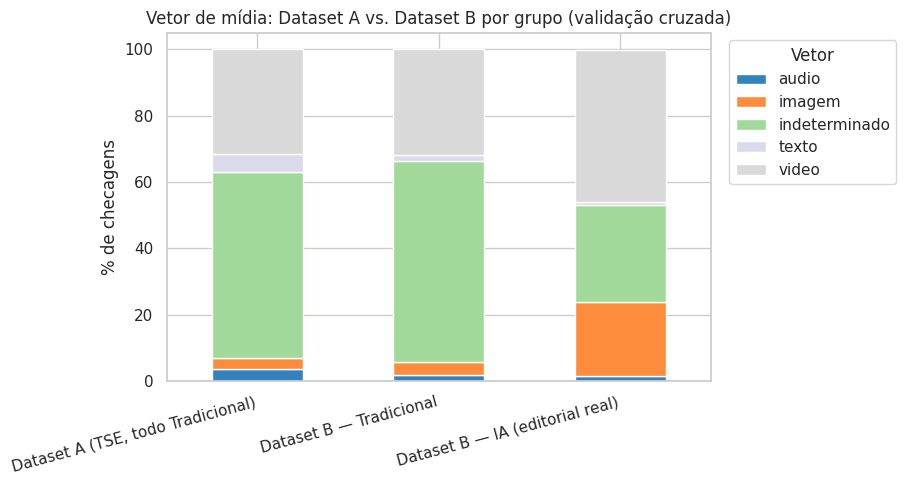

In [28]:

if comparacao is not None:
    fig, ax = plt.subplots(figsize=(9, 5))
    comparacao.T.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax)
    ax.set_title("Vetor de mídia: Dataset A vs. Dataset B por grupo (validação cruzada)")
    ax.set_ylabel("% de checagens"); ax.set_xlabel("")
    ax.legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout(); plt.show()


### 6.2 Sobreposição de títulos entre Dataset A e Dataset B (preview do Dataset C)
Antes de propor o Dataset C unificado (Seção 8), vale checar se A e B realmente descrevem boatos diferentes ou se há sobreposição direta de título — o que ajudaria a preencher datas ausentes do Dataset B via correspondência com o Dataset A.

In [29]:

if df_a_disponivel:
    titulos_a = set(df_a["titulo"].str.strip().str.lower())
    titulos_b = set(df["titulo"].str.strip().str.lower())
    overlap_exato = titulos_a & titulos_b
    print(f"Títulos idênticos (comparação exata, case-insensitive) entre A ({len(titulos_a)}) e B ({len(titulos_b)}): {len(overlap_exato)}")
    if overlap_exato:
        print(sorted(overlap_exato)[:10])
    print("\nComo esperado, a sobreposição exata é baixa/nula — os dois sites redigem título próprio")
    print("para o mesmo boato, então o cruzamento real do Dataset C precisará de similaridade textual")
    print("(ex.: TF-IDF + cosine similarity, ou fuzzy matching), não de comparação exata de string.")


Títulos idênticos (comparação exata, case-insensitive) entre A (228) e B (541): 4
['boletins de urna mostrados em vídeo não são de mg nem provam fraude', 'carregamento de cartão de memória usado em urna eletrônica não favorece ação de hackers', 'vídeo engana ao afirmar que fotos de candidatos foram trocadas em sapiranga (rs)', 'é falso que tse ordenou que todos os vídeos dos atos de 7 de setembro sejam excluídos da internet']

Como esperado, a sobreposição exata é baixa/nula — os dois sites redigem título próprio
para o mesmo boato, então o cruzamento real do Dataset C precisará de similaridade textual
(ex.: TF-IDF + cosine similarity, ou fuzzy matching), não de comparação exata de string.


## 7. Salvar dataset enriquecido

In [30]:

df_salvar = df.drop(columns=["titulo_norm", "corpo_norm"])
df_salvar.to_csv("../data/processed/dataset_b_aosfatos_enriquecido.csv", index=False)
print("Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv —", len(df_salvar), "linhas,",
      len(df_salvar.columns), "colunas (agora inclui data_publicacao_iso, dias_para_eleicao,",
      "vetor_midia_texto, alvo_ataque_texto [ambos via corpo_artigo, dicionário corrigido],",
      "texto_completo e corpo_artigo)")
df_salvar.drop(columns=["texto_completo", "corpo_artigo"]).sample(5, random_state=7)


Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv — 541 linhas, 16 colunas (agora inclui data_publicacao_iso, dias_para_eleicao, vetor_midia_texto, alvo_ataque_texto [ambos via corpo_artigo, dicionário corrigido], texto_completo e corpo_artigo)


,titulo,veredito,tema,tag_pesquisa,url,data_publicacao,data_publicacao_iso,rotulo_grupo,vetor_midia,alvo_ataque,ciclo_eleitoral_estimado,dias_para_eleicao,vetor_midia_texto,alvo_ataque_texto
333,Vídeo que mostra confusão entre petistas em Aracaju é de 2013 e não tem relação com at...,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/video-confusao-petistas-aracaju-2013-sem-relacao-ato...,"1 de outubro de 2022, 19:22",2022-10-01 19:22:00,Tradicional,video,candidato_pessoa,2022,-1,video,candidato_pessoa
216,É falso que Putin anunciou intervenção no Brasil em caso de fraude eleitoral,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/falso-putin-intervencao-brasil-fraude-eleitoral/,"8 de novembro de 2022, 14:31",2022-11-08 14:31:00,Tradicional,indeterminado,urna_processo,2022,37,video,indeterminado
441,É falso que STF e TSE criaram lei para cassar cristãos eleitos,falso,boataria política,eleicoes-2022,https://www.aosfatos.org/noticias/e-falso-que-stf-e-tse-criaram-lei-para-cassar-crista...,"29 de julho de 2022, 17:59",2022-07-29 17:59:00,Tradicional,indeterminado,urna_processo,2022,-65,video,indeterminado
218,"Vídeo de militares em estação de trem de Suzano é de 2018, não recente",falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/exercito-estacao-cptm-suzano-2018/,"7 de novembro de 2022, 16:37",2022-11-07 16:37:00,Tradicional,video,indeterminado,2022,36,video,indeterminado
424,Plano de governo de Bolsonaro contém falsidades sobre transparência e leis para mulheres,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/checamos-plano-governo-bolsonaro/,"10 de agosto de 2022, 19:11",2022-08-10 19:11:00,Tradicional,indeterminado,candidato_pessoa,2022,-53,indeterminado,candidato_pessoa


## 8. Limitações e próximos passos

- **Data de publicação e texto completo: limitação anterior, agora resolvida.** As versões anteriores deste notebook não tinham data por item nem o corpo da checagem — bloqueando H3/H5 e forçando `vetor_midia`/`alvo_ataque` a depender só do título. O usuário coletou localmente (fora do sandbox) a página individual das 553 checagens via `scripts/scrape_dataset_b_completo.py`; um bug na extração de data (quebra de linha entre "data" e "hora" no HTML — o texto real fica em 3 nós HTML separados: `"20 de agosto de 2026"`, `","`, `"15:57"`) zerava 100% das datas apesar do texto completo já ter sido baixado corretamente. Corrigido e reaplicado sobre o texto já coletado, sem nova requisição à internet, por `scripts/build_dataset_b_completo.py` — **553/553 (100%) das datas foram recuperadas**. Isso deixa de ser uma limitação a partir desta versão.
- **A data capturada é a de publicação da CHECAGEM pelo Aos Fatos, não a data em que o boato original começou a circular.** Há uma defasagem real entre o boato nascer nas redes e o Aos Fatos publicar a checagem (dias a semanas, tipicamente) — `dias_para_eleicao` e a análise de H5 (Seções 4.5, 5.1, 5.2) devem ser lidos como "quando a checagem saiu", um proxy razoável mas não idêntico a "quando a desinformação circulou". Isso é uma limitação inerente a qualquer dataset construído a partir de agências de checagem (também vale para o Dataset A), não um problema introduzido nesta coleta.
- **`eleicoes-2022` é população completa** (419 de 419 itens, 35/35 páginas) — a amostra de 7 páginas usada na primeira versão deste notebook foi substituída por uma coleta integral a pedido do usuário. Três páginas (13, 27, 31) exigiram nova tentativa por um glitch de cache do site que repetia o conteúdo da página anterior; cada uma foi confirmada como conteúdo único antes de aceita, e a checagem de duplicidade de títulos no dataset final (Seção 2) não encontrou nenhuma duplicata.
- **`rotulo_grupo` foi auditado contra contaminação entre tags** (Seção 4.1) — nenhum título aparece sob mais de uma tag pesquisada, então a atribuição IA vs. Tradicional pela tag de busca é segura para este dataset.
- **`tema` tem cobertura parcial** (Seção 4.2) — é uma anotação editorial opcional, não presente em todos os itens (mais comum dentro do grupo IA do que fora dele). Qualquer leitura de `tema` deve declarar o `n` efetivo, não `n=553`.
- **Contaminação lexical em `alvo_ataque_texto`: identificada E corrigida, em DUAS rodadas.** (1) Seção 3.5 — uma primeira tentativa de recalcular `vetor_midia`/`alvo_ataque` sobre `texto_completo` (dump da página inteira) gerou 0.0% de "indeterminado" em `alvo_ataque` no dataset inteiro — a nuvem de tags do rodapé (presente em toda página do site, com nomes como "Lula"/"Bolsonaro"/"TSE") estava contaminando o resultado. Corrigido isolando `corpo_artigo` (só o texto do artigo, sem nav/menu/rodapé) e removendo do dicionário as palavras genéricas demais (`"lula"`, `"bolsonaro"`, `"tse"`). (2) Seção 3.5b, descoberta na Fase 3 ao construir o classificador de ML (`models/`) — mesmo dentro de `corpo_artigo` restava um quadro de metodologia padronizado ("o caminho da apuração...") presente em 86.9% dos itens IA contra 5.3% dos Tradicionais, e a palavra "apuração" é literalmente uma das palavras-chave de `urna_processo`. Corrigido removendo esse boilerplate (mesma limpeza usada em `models/src/models_pkg/data/boilerplate.py`) antes de recalcular. `vetor_midia_texto` não foi afetado por nenhuma das duas rodadas (0 itens mudaram de classificação); `alvo_ataque_texto` mudou bastante nas duas.
- **O achado de H4 mudou de direção DUAS vezes ao longo dessas correções — a versão final é a Seção 4.4b.** Com a heurística totalmente contaminada (só título, ou dicionário genérico demais), o grupo IA nunca aparecia atacando o processo/urna. Depois da 1ª correção (Seção 3.5), o padrão parecia se inverter: IA passava a ser proporcionalmente MAIS `urna_processo` que o Tradicional (chi2=76.172, p<0.0001, V=0.371) — esse foi o resultado registrado nas versões anteriores deste notebook e no README do projeto. A 2ª correção (Seção 3.5b) mostrou que esse resultado era, ele mesmo, um artefato lexical: a esmagadora maioria dos itens "urna_processo" do grupo IA só carregava essa etiqueta por causa da frase-modelo "o caminho da apuração", sem relação com o conteúdo do boato. Com o boilerplate removido, o padrão se inverte de novo — desta vez com um efeito mais forte (V de Cramér maior) e alinhado com a direção original de H4: o grupo IA é muito mais associado a ataques à pessoa do candidato do que o grupo Tradicional. **Lição registrada duas vezes neste notebook:** um achado contraintuitivo baseado em heurística de palavra-chave pede auditoria da heurística antes de qualquer interpretação substantiva — e essa auditoria pode precisar de mais de uma rodada.
- **O confundimento de desenho amostral em `dias_para_eleicao` foi identificado E corrigido nesta versão (Seção 4.5).** O teste ingênuo (toda a amostra) encontra uma diferença grande e altamente significativa (mediana Tradicional ≈ -2 dias do 1º turno; mediana IA ≈ +140 dias; Mann-Whitney p<0.0001) — mas boa parte dela vem de como as tags foram definidas: `eleicoes-2022` (quase todo o grupo Tradicional) é um recorte por ano eleitoral (89% dos itens publicados no próprio ano do pleito), enquanto `inteligencia-artificial` é um recorte por tema, sem filtro de proximidade eleitoral (77% publicados em 2024-2025, anos sem eleição geral). Corrigido restringindo a comparação a uma janela temporal equivalente ao redor da eleição para os dois grupos: com janelas de ±200 ou ±180 dias, **a diferença deixa de ser estatisticamente significativa** (p≈0.66 e p≈0.78, contra p<0.0001 no teste ingênuo). Conclusão honesta: quase todo o efeito do teste ingênuo era o confundimento de amostragem, não H5 — este dataset, do jeito que foi coletado, não sustenta a alegação de aceleração temporal do grupo IA. Não é uma refutação de H5 (a amostra IA fica pequena dentro da janela estreita, n=47-52), só uma correção do teste anterior. Fase 3 precisa de uma coleta desenhada especificamente para isolar esse efeito.
- **Validação cruzada informal via `vetor_midia`** (Seção 6.1, baseada na versão por título): a baseline Tradicional do Dataset B e o Dataset A inteiro convergem de forma consistente (~29-31% vídeo, ~59-61% indeterminado) apesar de serem coletas independentes — evidência indireta de que a heurística não é ruído aleatório. O grupo IA se destaca claramente das duas baselines (~48% audiovisual vs. ~32-33%). Essa comparação ainda usa a versão por título dos dois lados (Dataset A só tem título+resumo, não o corpo completo do TSE) — não é diretamente comparável à versão de texto completo introduzida nesta versão só para o Dataset B.
- **Teste de Mann-Whitney para `dias_para_eleicao`** (Seção 4.5) assume que as duas amostras (IA/Tradicional) são independentes, o que vale aqui (nenhum item pertence aos dois grupos, Seção 4.1), mas não controla por possível viés de cobertura do Aos Fatos ao longo do tempo (ex.: se a agência passou a publicar mais checagens de IA especificamente a partir de um certo ano, isso confundiria "aceleração perto da eleição" com "aumento geral de cobertura do tema IA"). Não investigado nesta versão — fica para a Fase 3.
- Próximo passo natural: consolidar A + B no **Dataset C (unificado)**. A Seção 6.2 confirma que a sobreposição exata de título é baixa (4 de 322/553 itens) — o cruzamento real vai precisar de similaridade textual (TF-IDF/fuzzy matching), não comparação exata.
